# 02 · Missing values and outliers

SPEC 03, roadmap 2.3 to 2.5. Train races only. It looks at each feature on its own: distribution, missing
values and why they are missing, the rows the valid-row rule drops, outliers of the features and of the
target (genuine or error), and the 3% cap on `quali_delta_pct`. Intervals resample whole races.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parents[1]
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "notebooks" / "exploratory")]

from provisional import DATASET_PATH  # noqa: E402

from common.config import load_config  # noqa: E402

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update(
    {"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False}
)
SEED = load_config().optuna.seed
rng = np.random.default_rng(SEED)
df = pd.read_parquet(DATASET_PATH)
valid = df[df["is_valid_row"]].copy()
n_races = valid[["year", "round"]].drop_duplicates().shape[0]
print(f"{len(df)} rows, {len(valid)} valid, {n_races} train races, seed {SEED}")
from provisional import read_tables  # noqa: E402
from scipy import stats  # noqa: E402

from ingestion.session import RAW_DIR  # noqa: E402


def race_bootstrap(stat, frame=None, draws=1000):
    """95% interval of `stat(frame)` resampling whole races, never single rows."""
    frame = valid if frame is None else frame
    key = frame["year"].astype(str) + "-" + frame["round"].astype(str)
    groups = [g.index.to_numpy() for _, g in frame.groupby(key)]
    values = []
    for _ in range(draws):
        pick = rng.integers(0, len(groups), len(groups))
        values.append(stat(frame.loc[np.concatenate([groups[i] for i in pick])]))
    return np.percentile(values, [2.5, 97.5]).round(3)


TARGET = "race_pace_delta_pct"
NUMERIC = [
    "quali_delta_pct", "grid_position", "reached_q3", "fp_long_run_delta_pct", "fp_tyre_deg",
    "driver_pace_last3", "team_pace_last3", "teammate_quali_gap", "team_pace_this_circuit_prev",
    "track_temp", "air_temp", "rain_flag", "sprint_pace_delta_pct", "is_sprint_weekend",
]  # fmt: skip
CATEGORICAL = ["circuit_type"]
EXPLORATION_ONLY = ["humidity", "wind_speed"]
for column in NUMERIC:
    valid[column] = valid[column].astype(float)
print(len(NUMERIC) + len(CATEGORICAL), "catalog features;", len(valid), "training rows")

1118 rows, 1050 valid, 56 train races, seed 42


15 catalog features; 1050 training rows


## 1. Distribution of each feature

In [2]:
desc = valid[NUMERIC + EXPLORATION_ONLY].describe(percentiles=[0.01, 0.5, 0.99]).T
desc = desc[["count", "mean", "std", "min", "1%", "50%", "99%", "max"]]
desc["skew"] = valid[NUMERIC + EXPLORATION_ONLY].skew()
print(desc.round(2).to_string())

                              count   mean    std    min     1%    50%    99%    max  skew
quali_delta_pct              1050.0   1.68   2.52   0.00   0.00   1.21  13.77  45.60  7.68
grid_position                1048.0  10.24   5.71   1.00   1.00  10.00  20.00  20.00  0.03
reached_q3                   1050.0   0.50   0.50   0.00   0.00   1.00   1.00   1.00 -0.02
fp_long_run_delta_pct         594.0  -0.06   0.88 -12.22  -1.69  -0.06   2.06   3.98 -4.09
fp_tyre_deg                   594.0   0.13   0.25  -1.22  -0.52   0.12   0.93   1.56  0.47
driver_pace_last3            1022.0   0.03   0.80  -1.69  -1.52   0.11   1.58   6.15  1.05
team_pace_last3              1030.0   0.03   0.72  -1.65  -1.44   0.15   1.39   3.06  0.08
teammate_quali_gap           1040.0  -0.00   2.35 -29.97  -5.99  -0.01   6.37  42.80  3.94
team_pace_this_circuit_prev   594.0   0.02   0.78  -2.06  -1.75   0.05   1.68   2.35  0.02
track_temp                   1050.0  33.70   8.71  14.07  14.07  34.15  48.73  48.73 -0.28

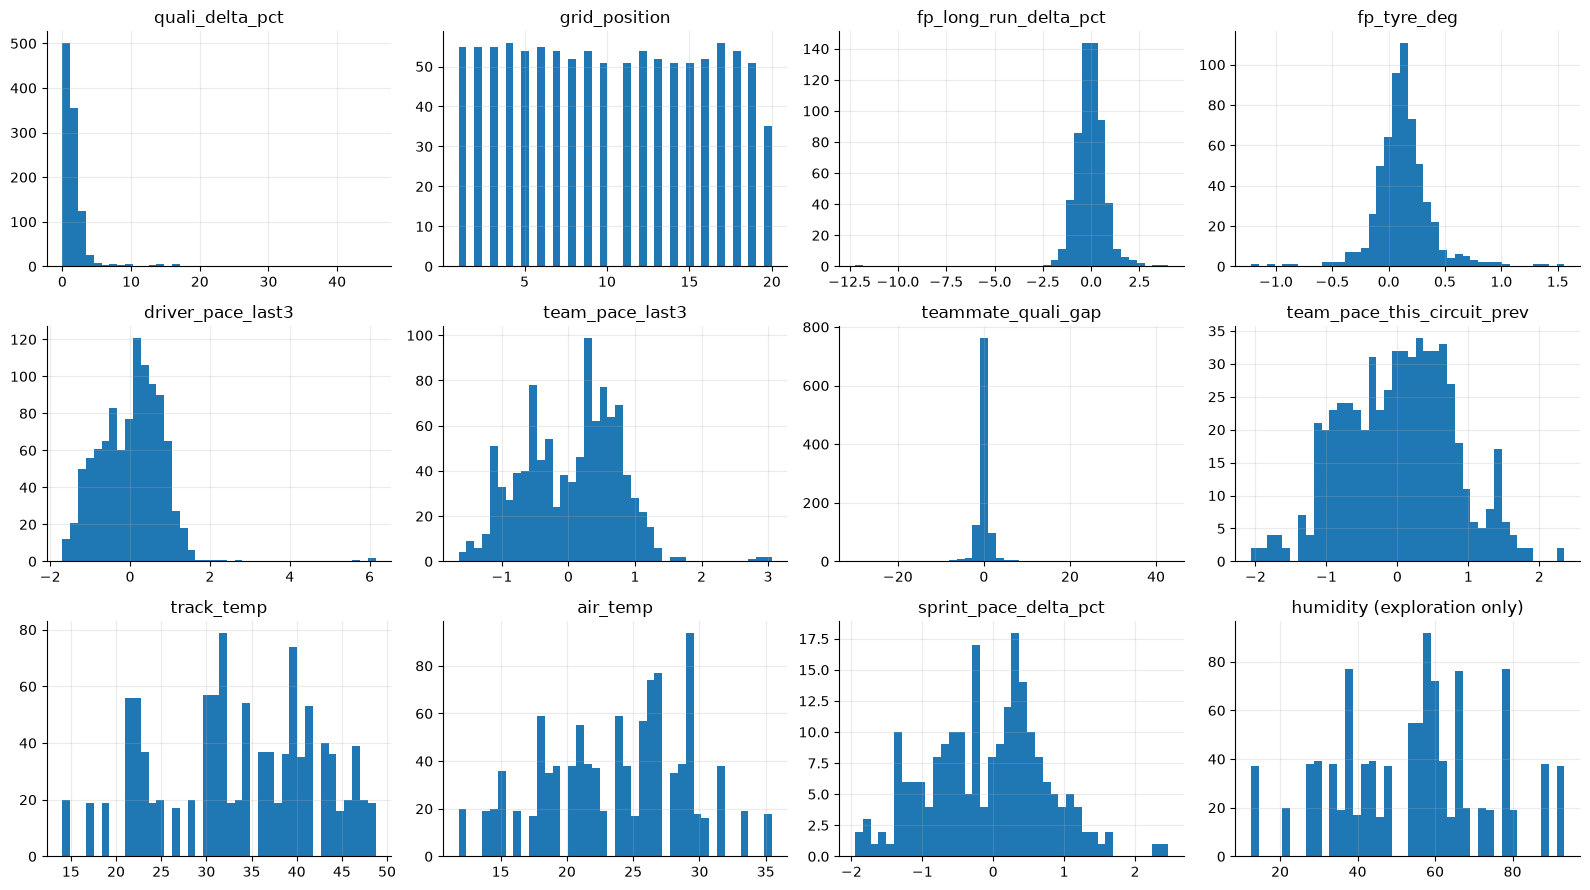

In [3]:
continuous = ["quali_delta_pct", "grid_position", "fp_long_run_delta_pct", "fp_tyre_deg", "driver_pace_last3",
              "team_pace_last3", "teammate_quali_gap", "team_pace_this_circuit_prev", "track_temp", "air_temp",
              "sprint_pace_delta_pct", "humidity"]  # fmt: skip
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, column in zip(axes.ravel(), continuous, strict=True):
    ax.hist(valid[column].dropna(), bins=40)
    ax.set(title=column + (" (exploration only)" if column in EXPLORATION_ONLY else ""))
plt.tight_layout()
plt.show()

## 2. Categorical features: cardinality and rare levels

`circuit_type` is the only categorical feature. Team, circuit and driver are identification columns, not
predictors, but their levels show how thin the form features are.

In [4]:
races_per_type = valid.groupby("circuit_type")[["year", "round"]].apply(lambda g: len(g.drop_duplicates()))
print(pd.DataFrame({"rows": valid["circuit_type"].value_counts(), "races": races_per_type}).to_string(), "\n")
for column in ("team", "circuit", "driver"):
    counts = valid[column].value_counts()
    low, mid, high = counts.min(), int(counts.median()), counts.max()
    print(f"{column}: {len(counts)} levels, rows per level min {low} / median {mid} / max {high}")
by_circuit = valid.groupby("circuit")[["year", "round"]].apply(lambda g: len(g.drop_duplicates()))
print("\ncircuits raced once in the train races:", sorted(by_circuit[by_circuit == 1].index))
few = valid["driver"].value_counts()
print("drivers with fewer than 25 valid rows:", few[few < 25].to_dict())

              rows  races
circuit_type             
hybrid         166      9
permanent      659     35
street         225     12 

team: 10 levels, rows per level min 97 / median 105 / max 110
circuit: 24 levels, rows per level min 35 / median 38 / max 60
driver: 28 levels, rows per level min 5 / median 47 / max 56

circuits raced once in the train races: []
drivers with fewer than 25 valid rows: {'RIC': 24, 'LAW': 20, 'COL': 12, 'BEA': 11, 'ANT': 10, 'DEV': 9, 'BOR': 9, 'HAD': 9, 'DOO': 5}


## 3. Missing values

Share of NaN per column on the training rows. Most NaN here are **structural**, a feature that cannot exist for
that row (no FP2 on a sprint weekend, no previous year for 2023), not data that went missing at random.

In [5]:
nan_share = valid[NUMERIC + CATEGORICAL + EXPLORATION_ONLY].isna().mean().sort_values(ascending=False)
print((nan_share[nan_share > 0] * 100).round(1).rename("% NaN").to_string())
sprint = valid["is_sprint_weekend"] == 1
rows_off = (valid["sprint_pace_delta_pct"].isna() == ~sprint).mean()
print(f"\nsprint_pace_delta_pct is NaN exactly on normal weekends: consistent in {rows_off:.1%} of rows")
fp = valid["fp_long_run_delta_pct"].isna()
print(
    "FP2 features NaN on sprint weekends:",
    f"{fp[sprint].mean():.1%} of {sprint.sum()} rows;",
    "on normal weekends:",
    f"{fp[~sprint].mean():.1%} of {(~sprint).sum()} rows",
)
print("same pattern for fp_tyre_deg:", bool((valid["fp_tyre_deg"].isna() == fp).all()))

sprint_pace_delta_pct          79.4
team_pace_this_circuit_prev    43.4
fp_long_run_delta_pct          43.4
fp_tyre_deg                    43.4
driver_pace_last3               2.7
team_pace_last3                 1.9
teammate_quali_gap              1.0
grid_position                   0.2

sprint_pace_delta_pct is NaN exactly on normal weekends: consistent in 95.9% of rows
FP2 features NaN on sprint weekends: 100.0% of 259 rows; on normal weekends: 24.9% of 791 rows
same pattern for fp_tyre_deg: True


In [6]:
normal = valid[~sprint]
coverage = normal.groupby(["year", "round"])["fp_long_run_delta_pct"].apply(lambda s: s.notna().mean())
print("normal weekends, share of drivers with an FP2 long run, per race:")
print(coverage.describe().round(2).to_string())
print(
    f"races with no driver at all: {(coverage == 0).sum()}; with under 40%: {(coverage < 0.4).sum()} of {len(coverage)}"
)
weak = (
    coverage[coverage < 0.4]
    .reset_index()
    .merge(valid.groupby(["year", "round"])[["circuit", "rain_flag"]].first().reset_index(), on=["year", "round"])
)
weak.columns = ["year", "round", "coverage", "circuit", "rain_in_q"]
print(weak.round(2).to_string(index=False))

normal weekends, share of drivers with an FP2 long run, per race:
count    42.00
mean      0.75
std       0.32
min       0.00
25%       0.82
50%       0.89
75%       0.95
max       1.00
races with no driver at all: 2; with under 40%: 8 of 42
 year  round  coverage            circuit  rain_in_q
 2023      3      0.24          Melbourne        1.0
 2023      5      0.10              Miami        0.0
 2023     14      0.05              Monza        0.0
 2023     22      0.37 Yas Marina Circuit        0.0
 2024      4      0.00             Suzuka        0.0
 2024      9      0.05           Montreal        1.0
 2025      3      0.00             Suzuka        0.0
 2025      5      0.11             Jeddah        0.0


In [7]:
prev = valid["team_pace_this_circuit_prev"].isna()
first_year = valid["year"] == valid["year"].min()
print(
    "team_pace_this_circuit_prev NaN:",
    prev.sum(),
    "rows;",
    f"{(prev & first_year).sum()} in {valid['year'].min()}",
    "(no earlier year)",
)
later = valid[prev & ~first_year]
print(f"after the first year: {len(later)} rows in", later[["year", "round"]].drop_duplicates().shape[0], "races")
print(later.groupby(["year", "circuit"]).size().rename("rows").to_string())

team_pace_this_circuit_prev NaN: 456 rows; 413 in 2023 (no earlier year)
after the first year: 43 rows in 4 races
year  circuit    
2024  Hungaroring     2
      Imola          19
      Shanghai       20
2025  Monte Carlo     2


In [8]:
ordered = valid.sort_values(["year", "round"])
no_form = ordered[ordered["driver_pace_last3"].isna()]
first_seen = ordered.groupby("driver")[["year", "round"]].first()
is_first = no_form.apply(lambda r: (r["year"], r["round"]) == tuple(first_seen.loc[r["driver"]]), axis=1)
print("driver_pace_last3 NaN:", len(no_form), "rows; first valid race of the driver:", int(is_first.sum()))
print(no_form.loc[~is_first, ["year", "round", "driver"]].to_string(index=False))
print(
    "\nteam_pace_last3 NaN:",
    int(ordered["team_pace_last3"].isna().sum()),
    "rows; teammate_quali_gap NaN:",
    int(ordered["teammate_quali_gap"].isna().sum()),
    "rows",
)
print(ordered[ordered["teammate_quali_gap"].isna()].groupby(["year", "round"]).size().rename("rows").to_string())

driver_pace_last3 NaN: 28 rows; first valid race of the driver: 28
Empty DataFrame
Columns: [year, round, driver]
Index: []

team_pace_last3 NaN: 20 rows; teammate_quali_gap NaN: 10 rows
year  round
2023  3        1
      16       1
      19       1
      22       1
2024  2        1
      3        1
      7        1
      17       1
2025  1        1
      7        1


In [9]:
grid_nan = df[df["grid_position"].isna()]
print(
    "grid_position NaN in the whole file:",
    len(grid_nan),
    "rows; with a qualifying time:",
    int(grid_nan["quali_delta_pct"].notna().sum()),
    "| in training rows:",
    int(valid["grid_position"].isna().sum()),
)
with_time = grid_nan[grid_nan["quali_delta_pct"].notna()]
print(
    with_time[["year", "round", "driver", "quali_delta_pct", "reached_q3", "is_valid_row"]]
    .round(2)
    .to_string(index=False)
)
flags = []
for year, rnd in with_time[["year", "round"]].drop_duplicates().itertuples(index=False):
    session_result, drivers = read_tables(year, rnd, "Q", ("session_result", "drivers"))
    missing = session_result[session_result["position"].isna()].merge(
        drivers[["driver_number", "name_acronym"]], on="driver_number"
    )
    flags.append(missing.assign(year=year, round=rnd)[["year", "round", "name_acronym", "dnf", "dns", "dsq"]])
print("\nflags in the source `session_result`:")
print(pd.concat(flags).to_string(index=False))

grid_position NaN in the whole file: 15 rows; with a qualifying time: 5 | in training rows: 2
 year  round driver  quali_delta_pct  reached_q3  is_valid_row
 2023      2    SAR            45.60           0          True
 2023      4    DEV            15.05           0         False
 2023     10    BOT             3.55           0          True
 2024      8    MAG             2.07           0         False
 2024      8    HUL             1.67           0         False

flags in the source `session_result`:
 year  round name_acronym   dnf   dns   dsq
 2023      2          SAR False False False
 2023      4          DEV False False False
 2023     10          BOT False False False
 2024      8          HUL False False False
 2024      8          MAG False False False


In [10]:
structural = pd.DataFrame(
    {
        "sprint_pace_delta_pct": ~sprint,
        "fp_long_run_delta_pct": sprint,
        "fp_tyre_deg": sprint,
        "team_pace_this_circuit_prev": first_year,
    }
)
unexpected = valid[NUMERIC].isna() & ~structural.reindex(columns=NUMERIC, fill_value=False)
per_row = unexpected.sum(axis=1)
print("unexpected NaN per training row (structural ones removed):")
print(per_row.value_counts().sort_index().to_string())
print(f"complete rows once structural NaN are set aside: {(per_row == 0).mean():.1%}")
any_nan = valid[NUMERIC].isna().sum(axis=1)
print(f"NaN per row counting all of them: median {int(any_nan.median())}, max {any_nan.max()}")

unexpected NaN per training row (structural ones removed):
0    735
1     98
2    210
3      6
4      1
complete rows once structural NaN are set aside: 70.0%
NaN per row counting all of them: median 2, max 6


## 4. Does missingness relate to the target?

For each feature with NaN, the median target of the rows where it is missing minus where it is present, with a
95% interval that resamples whole races. An interval away from 0 means the NaN carry information on their own.

In [11]:
def gap(column):
    def stat(frame):
        missing = frame[column].isna()
        return frame.loc[missing, TARGET].median() - frame.loc[~missing, TARGET].median()

    return stat


rows = []
for column in (
    "fp_long_run_delta_pct",
    "team_pace_this_circuit_prev",
    "sprint_pace_delta_pct",
    "driver_pace_last3",
    "team_pace_last3",
    "teammate_quali_gap",
    "quali_delta_pct",
):
    stat = gap(column)
    if valid[column].isna().sum() < 5:
        continue
    low, high = race_bootstrap(stat, draws=400)
    rows.append(
        {
            "feature": column,
            "n_missing": int(valid[column].isna().sum()),
            "median gap (missing - present)": round(stat(valid), 3),
            "ci_low": low,
            "ci_high": high,
        }
    )
print(pd.DataFrame(rows).to_string(index=False))

                    feature  n_missing  median gap (missing - present)  ci_low  ci_high
      fp_long_run_delta_pct        456                          -0.094  -0.166    0.032
team_pace_this_circuit_prev        456                          -0.089  -0.139   -0.009
      sprint_pace_delta_pct        834                          -0.025  -0.084    0.117
          driver_pace_last3         28                          -0.048  -0.219    0.761
            team_pace_last3         20                          -0.120     NaN      NaN
         teammate_quali_gap         10                           0.295  -0.484    1.405


In [12]:
# The structural NaN again, inside the groups they define: is the target different where FP2 is absent?
def median_gap(mask):
    return valid.loc[mask, TARGET].median() - valid.loc[~mask, TARGET].median()


print(
    "sprint weekend vs normal weekend, median target gap:",
    round(median_gap(sprint), 3),
    race_bootstrap(
        lambda f: (
            f.loc[f["is_sprint_weekend"] == 1, TARGET].median() - f.loc[f["is_sprint_weekend"] == 0, TARGET].median()
        ),
        draws=400,
    ),
)
spread = valid.groupby("is_sprint_weekend")[TARGET].agg(["size", "median", "std"]).round(3)
print(spread.to_string())

sprint weekend vs normal weekend, median target gap: 0.004 [-0.133  0.074]
                   size  median    std
is_sprint_weekend                     
0.0                 791   0.057  1.074
1.0                 259   0.061  0.772


## 5. Imputation choice per column

The training config offers `median` or `mean` (an Optuna choice inside each model's pipeline). Nothing is
imputed here; the table shows what each column would need. A mean and a median that disagree by a large
share of the standard deviation, or a skewed column, points to the median.

In [13]:
mechanism = {
    "sprint_pace_delta_pct": "structural: normal weekend (no sprint)",
    "fp_long_run_delta_pct": "structural: sprint weekend (no FP2); otherwise no long run found",
    "fp_tyre_deg": "same as fp_long_run_delta_pct",
    "team_pace_this_circuit_prev": "structural: first year, or circuit not raced the year before",
    "driver_pace_last3": "first valid race of the driver",
    "team_pace_last3": "first race of the team lineage",
    "teammate_quali_gap": "no teammate or no time",
    "grid_position": "source gives no position",
}
table = []
for column in NUMERIC:
    x = valid[column]
    if x.isna().sum() == 0:
        continue
    table.append(
        {
            "column": column,
            "% NaN": round(100 * x.isna().mean(), 1),
            "skew": round(x.skew(), 2),
            "|mean-median|/std": round(abs(x.mean() - x.median()) / x.std(), 2),
            "mechanism": mechanism.get(column, ""),
        }
    )
print(pd.DataFrame(table).sort_values("% NaN", ascending=False).to_string(index=False))

                     column  % NaN  skew  |mean-median|/std                                                        mechanism
      sprint_pace_delta_pct   79.4  0.05               0.09                           structural: normal weekend (no sprint)
      fp_long_run_delta_pct   43.4 -4.09               0.00 structural: sprint weekend (no FP2); otherwise no long run found
                fp_tyre_deg   43.4  0.47               0.04                                    same as fp_long_run_delta_pct
team_pace_this_circuit_prev   43.4  0.02               0.04     structural: first year, or circuit not raced the year before
          driver_pace_last3    2.7  1.05               0.10                                   first valid race of the driver
            team_pace_last3    1.9  0.08               0.16                                   first race of the team lineage
         teammate_quali_gap    1.0  3.94               0.00                                           no teammate or no time


## 6. Rows the valid-row rule drops

A row is valid with a qualifying time and at least 10 clean laps. Is the loss random, and is 10 the right
threshold? The clean-lap bands compare how noisy the target is for drivers close to the threshold.

In [14]:
dropped = df[~df["is_valid_row"]].copy()
dropped["reason"] = np.where(dropped["quali_delta_pct"].isna(), "no qualifying time", "under 10 clean laps")
print(dropped["reason"].value_counts().to_string(), "\n")
by = pd.DataFrame(
    {
        "rows": df.groupby("year").size(),
        "dropped": dropped.groupby("year").size(),
    }
)
by["% dropped"] = (100 * by["dropped"] / by["rows"]).round(1)
print(by.to_string(), "\n")
for column in ("circuit_type", "rain_flag", "is_sprint_weekend", "team"):
    share = df.groupby(column)["is_valid_row"].apply(lambda s: round(100 * (~s).mean(), 1)).rename("% dropped")
    print(share.sort_values(ascending=False).to_string(), "\n")
worst = dropped.groupby(["year", "round", "circuit"]).size().rename("dropped").sort_values(ascending=False).head(8)
print(worst.to_string())

reason
under 10 clean laps    58
no qualifying time     10 

      rows  dropped  % dropped
year                          
2023   440       27        6.1
2024   478       27        5.6
2025   200       14        7.0 

circuit_type
hybrid       7.3
street       6.2
permanent    5.7 

rain_flag
0    6.3
1    5.4 

is_sprint_weekend
1    7.5
0    5.6 

team
Williams           11.8
Alpine             11.6
RB                  7.1
Red Bull Racing     7.1
Aston Martin        6.2
Haas F1 Team        5.4
Kick Sauber         4.5
Ferrari             2.7
McLaren             2.7
Mercedes            1.8 

year  round  circuit    
2024  8      Monte Carlo    4
2025  6      Miami          4
      1      Melbourne      4
2023  3      Melbourne      3
      20     Interlagos     3
2024  20     Mexico City    3
      4      Suzuka         3
      23     Lusail         3


In [15]:
bands = pd.cut(valid["clean_laps"], [9, 14, 24, 39, 100], labels=["10-14", "15-24", "25-39", "40+"])
band_stats = valid.groupby(bands, observed=True)[TARGET].agg(
    rows="size",
    std="std",
    mad=lambda s: stats.median_abs_deviation(s, scale="normal"),
    share_over_2=lambda s: (s.abs() > 2).mean(),
)
print(band_stats.round(3).to_string(), "\n")
with_time = df[df["quali_delta_pct"].notna()]
sens = pd.Series({k: int((with_time["clean_laps"] < k).sum()) for k in (5, 8, 10, 12, 15, 20, 25)})
print("rows with a qualifying time that a minimum of k clean laps would drop:")
print(sens.rename("rows").to_string())

            rows    std    mad  share_over_2
clean_laps                                  
10-14          9  5.221  0.837         0.333
15-24         14  0.833  0.655         0.143
25-39         97  0.891  0.944         0.031
40+          930  0.833  0.878         0.010 

rows with a qualifying time that a minimum of k clean laps would drop:
5     47
8     53
10    58
12    60
15    67
20    71
25    81


## 7. Outliers of the features

A value is flagged when it is more than 4 robust standard deviations (MAD) from the median. Each flagged group is
then read against the raw session to decide whether it is genuine (a real slow lap, rain, a crash) or an error.

In [16]:
rows = []
for column in NUMERIC + EXPLORATION_ONLY:
    x = valid[column].dropna()
    if x.nunique() <= 3:
        continue
    robust_z = (x - x.median()).abs() / stats.median_abs_deviation(x, scale="normal")
    rows.append(
        {
            "feature": column,
            "n": len(x),
            "flagged (>4 MAD)": int((robust_z > 4).sum()),
            "min": x.min(),
            "max": x.max(),
            "median": x.median(),
        }
    )
print(pd.DataFrame(rows).round(2).to_string(index=False))

                    feature    n  flagged (>4 MAD)    min   max  median
            quali_delta_pct 1050                39   0.00 45.60    1.21
              grid_position 1048                 0   1.00 20.00   10.00
      fp_long_run_delta_pct  594                 5 -12.22  3.98   -0.06
                fp_tyre_deg  594                15  -1.22  1.56    0.12
          driver_pace_last3 1022                 3  -1.69  6.15    0.11
            team_pace_last3 1030                 0  -1.65  3.06    0.15
         teammate_quali_gap 1040                52 -29.97 42.80   -0.01
team_pace_this_circuit_prev  594                 0  -2.06  2.35    0.05
                 track_temp 1050                 0  14.07 48.73   34.15
                   air_temp 1050                 0  11.83 35.46   24.38
      sprint_pace_delta_pct  216                 0  -1.95  2.47   -0.01
                   humidity 1050                 0  12.53 93.36   56.58
                 wind_speed 1050                 0   0.58  4.14 

In [17]:
def q_info(row):
    result, drivers = read_tables(row["year"], row["round"], "Q", ("session_result", "drivers"))
    (control,) = read_tables(row["year"], row["round"], "Q", ("race_control",))
    number = drivers.loc[drivers["name_acronym"] == row["driver"], "driver_number"].iloc[0]
    mine = result[result["driver_number"] == number].iloc[0]
    return pd.Series(
        {
            "q_laps": mine["number_of_laps"],
            "q1_s": np.asarray(mine["duration"], dtype=float)[0],
            "q_red_flags": int(((control["flag"] == "RED") & (control["scope"] == "Track")).sum()),
            "dnf": bool(mine["dnf"]),
        }
    )


wide = valid[valid["quali_delta_pct"] > 3].copy()
print(f"quali_delta_pct above 3%: {len(wide)} training rows ({len(wide) / valid['quali_delta_pct'].notna().sum():.1%})")
print(
    wide.groupby("year").size().rename("rows").to_dict(),
    "| rain in Q:",
    int(wide["rain_flag"].sum()),
    "| reached Q3:",
    int(wide["reached_q3"].sum()),
)
top = wide.nlargest(12, "quali_delta_pct")
shown = top[["year", "round", "circuit", "driver", "team", "quali_delta_pct", "rain_flag", TARGET, "clean_laps"]]
print(
    pd.concat([shown.reset_index(drop=True), top.apply(q_info, axis=1).reset_index(drop=True)], axis=1)
    .round(2)
    .to_string(index=False)
)

quali_delta_pct above 3%: 85 training rows (8.1%)
{2023: 52, 2024: 30, 2025: 3} | rain in Q: 58 | reached Q3: 1


 year  round           circuit driver            team  quali_delta_pct  rain_flag  race_pace_delta_pct  clean_laps  q_laps   q1_s  q_red_flags   dnf
 2023      2            Jeddah    SAR        Williams            45.60        0.0                 0.78          45       8 128.51            0 False
 2023     13         Zandvoort    LAW              RB            18.21        1.0                 1.02          55      12  83.42            2 False
 2023     13         Zandvoort    BOT     Kick Sauber            16.57        1.0                 1.17          58      12  82.26            2 False
 2023     13         Zandvoort    MAG    Haas F1 Team            16.47        1.0                 0.52          55      11  82.19            2 False
 2023     13         Zandvoort    OCO          Alpine            16.36        1.0                -0.38          54      12  82.11            2 False
 2023     13         Zandvoort    ZHO     Kick Sauber            16.30        1.0                 0.03    

In [18]:
mates = valid.loc[
    valid["teammate_quali_gap"].abs() > 8, ["year", "round", "driver", "team", "quali_delta_pct", "teammate_quali_gap"]
]
print("teammate_quali_gap beyond +-8%:", len(mates), "rows")
print(mates.round(2).to_string(index=False))

teammate_quali_gap beyond +-8%: 11 rows
 year  round driver            team  quali_delta_pct  teammate_quali_gap
 2023      2    SAR        Williams            45.60               42.80
 2023      2    ALB        Williams             1.96              -29.97
 2023      4    TSU              RB             1.36              -11.90
 2023     13    ALO    Aston Martin             1.33              -10.75
 2023     13    STR    Aston Martin            13.54               12.05
 2023     13    HAM        Mercedes            13.58               12.42
 2023     13    RUS        Mercedes             1.03              -11.05
 2024     12    VER Red Bull Racing             0.45              -12.35
 2024     12    PER Red Bull Racing            14.60               14.09
 2024     21    HAM        Mercedes             9.29                9.06
 2024     21    RUS        Mercedes             0.21               -8.31


In [19]:
from provisional import long_runs  # noqa: E402


def practice_row(row):
    laps, pit, control, stints = read_tables(
        row["year"], row["round"], "FP2", ("laps", "pit", "race_control", "stints")
    )
    numbers = pd.read_parquet(RAW_DIR / str(row["year"]) / f"{row['round']:02d}" / "Q" / "drivers.parquet")
    number = numbers.loc[numbers["name_acronym"] == row["driver"], "driver_number"].iloc[0]
    runs = [r for r in long_runs(laps, pit, control, stints) if r["driver_number"].iloc[0] == number]
    return pd.Series(
        {"runs": len(runs), "laps_in_runs": sum(len(r) for r in runs), "longest": max(len(r) for r in runs)}
    )


for column, side in (
    ("fp_long_run_delta_pct", "smallest"),
    ("fp_long_run_delta_pct", "largest"),
    ("fp_tyre_deg", "smallest"),
    ("fp_tyre_deg", "largest"),
):
    pick = (valid.nsmallest if side == "smallest" else valid.nlargest)(4, column)
    detail = pick[["year", "round", "circuit", "driver", column, "rain_flag"]].reset_index(drop=True)
    print(f"{side} {column}")
    print(
        pd.concat([detail, pick.apply(practice_row, axis=1).reset_index(drop=True)], axis=1)
        .round(2)
        .to_string(index=False),
        "\n",
    )

smallest fp_long_run_delta_pct


 year  round   circuit driver  fp_long_run_delta_pct  rain_flag  runs  laps_in_runs  longest
 2023      3 Melbourne    RUS                 -12.22        1.0     1             5        5
 2025      4    Sakhir    ALO                  -2.34        0.0     1             8        8
 2023      8  Montreal    DEV                  -2.07        1.0     1             5        5
 2024     10 Catalunya    VER                  -1.96        0.0     2            12        7 



largest fp_long_run_delta_pct


 year  round            circuit driver  fp_long_run_delta_pct  rain_flag  runs  laps_in_runs  longest
 2023     22 Yas Marina Circuit    MAG                   3.98        0.0     1             7        7
 2024     18          Singapore    PIA                   3.41        0.0     1             5        5
 2024     15          Zandvoort    ZHO                   2.60        0.0     1            13       13
 2024     12        Silverstone    SAI                   2.53        1.0     1             7        7 

smallest fp_tyre_deg
 year  round     circuit driver  fp_tyre_deg  rain_flag  runs  laps_in_runs  longest
 2023      3   Melbourne    HUL        -1.22        1.0     1             5        5
 2023      3   Melbourne    MAG        -1.05        1.0     1             5        5
 2025      8 Monte Carlo    VER        -0.91        0.0     1             5        5
 2023      3   Melbourne    RUS        -0.86        1.0     1             5        5 



largest fp_tyre_deg


 year  round           circuit driver  fp_tyre_deg  rain_flag  runs  laps_in_runs  longest
 2024     18         Singapore    PIA         1.56        0.0     1             5        5
 2024     10         Catalunya    RUS         1.38        0.0     1             5        5
 2024     14 Spa-Francorchamps    GAS         1.33        1.0     1             5        5
 2023     21         Las Vegas    BOT         1.03        0.0     1             6        6 



In [20]:
contaminated = valid[(valid["driver_pace_last3"] > 3) | (valid["team_pace_last3"] > 2)]
print("rows whose form features are inflated by a single extreme target (driver form > 3 or team form > 2):")
print(
    contaminated[["year", "round", "driver", "team", "driver_pace_last3", "team_pace_last3"]]
    .round(2)
    .to_string(index=False)
)

rows whose form features are inflated by a single extreme target (driver form > 3 or team form > 2):
 year  round driver     team  driver_pace_last3  team_pace_last3
 2023     14    SAR Williams               6.15             3.06
 2023     14    ALB Williams              -0.04             3.06
 2023     15    SAR Williams               6.01             2.93
 2023     15    ALB Williams              -0.16             2.93
 2023     16    ALB Williams              -0.14             2.72
 2023     17    SAR Williams               5.58             0.64


## 8. Outliers of the target

The extreme row of `01_target`, and the next ones, read against the raw race.

In [21]:
big = valid[valid[TARGET].abs() > 2.5].sort_values(TARGET, ascending=False)
print(
    big[["year", "round", "circuit", "driver", "team", TARGET, "clean_laps", "quali_delta_pct", "rain_flag"]]
    .round(2)
    .to_string(index=False)
)

 year  round           circuit driver            team  race_pace_delta_pct  clean_laps  quali_delta_pct  rain_flag
 2023     13         Zandvoort    SAR        Williams                16.80          13             8.76        1.0
 2024      9          Montreal    SAR        Williams                 3.31          22             1.39        1.0
 2023     12 Spa-Francorchamps    SAI         Ferrari                 2.92          20             0.93        1.0
 2023      1            Sakhir    PIA         McLaren                 2.78          12             2.67        0.0
 2024     17              Baku    TSU              RB                 2.57          11             1.65        0.0
 2025      8       Monte Carlo    VER Red Bull Racing                -2.51          70             1.02        0.0
 2025      8       Monte Carlo    NOR         McLaren                -2.59          70             0.00        0.0
 2025      8       Monte Carlo    PIA         McLaren                -2.74      

In [22]:
from provisional import clean_laps  # noqa: E402

worst = valid.loc[valid[TARGET].idxmax()]
laps, pit, control = read_tables(worst["year"], worst["round"], "R", ("laps", "pit", "race_control"))
numbers = pd.read_parquet(RAW_DIR / str(worst["year"]) / f"{worst['round']:02d}" / "Q" / "drivers.parquet")
number = numbers.loc[numbers["name_acronym"] == worst["driver"], "driver_number"].iloc[0]
clean = clean_laps(laps, pit, control)
mine = clean[clean["driver_number"] == number]
others = clean[clean["driver_number"] != number]
print(
    f"{worst['driver']} {worst['circuit']} {int(worst['year'])} round {int(worst['round'])}: "
    f"{len(mine)} clean laps, lap numbers {mine['lap_number'].min()}-{mine['lap_number'].max()}, "
    f"median {mine['lap_duration'].median():.1f} s"
)
by_lap = others.groupby("lap_number")["lap_duration"].agg(["size", "median"])
overlap = by_lap.reindex(mine["lap_number"])
print(
    "field clean laps on the same lap numbers: median",
    f"{overlap['median'].median():.1f} s, drivers per lap (median) {int(overlap['size'].median())}",
)
print("field median over all its clean laps:", round(others["lap_duration"].median(), 1), "s")
print("race_control flags (track scope):", control[control["scope"] == "Track"][["flag"]].value_counts().to_dict())
print(
    "laps of the whole race with a time:",
    int(laps["lap_duration"].notna().sum()),
    "| max lap number:",
    int(laps["lap_number"].max()),
)

SAR Zandvoort 2023 round 13: 13 clean laps, lap numbers 2-14, median 89.9 s
field clean laps on the same lap numbers: median 84.6 s, drivers per lap (median) 16
field median over all its clean laps: 76.9 s
race_control flags (track scope): {('CLEAR',): 2, ('GREEN',): 2, ('CHEQUERED',): 1, ('RED',): 1}
laps of the whole race with a time: 1340 | max lap number: 72


In [23]:
def describe(frame):
    y = frame[TARGET]
    e = y - y.mean()
    return {
        "rows": len(y),
        "std": y.std(),
        "excess kurtosis": stats.kurtosis(y),
        "dummy MAE": (y - y.median()).abs().mean(),
        "RMSE/MAE": np.sqrt((e**2).mean()) / e.abs().mean(),
    }


rules = {
    "no rule (min 10 clean laps)": valid,
    "min 15 clean laps": valid[valid["clean_laps"] >= 15],
    "min 20 clean laps": valid[valid["clean_laps"] >= 20],
    "drop |target| > 5": valid[valid[TARGET].abs() <= 5],
}
winsor = valid.assign(**{TARGET: valid[TARGET].clip(-3.5, 3.5)})
rules["winsorise target at +-3.5"] = winsor
print(pd.DataFrame({name: describe(frame) for name, frame in rules.items()}).T.round(3).to_string())
print("rows changed by the winsorising:", int((valid[TARGET].abs() > 3.5).sum()))

                               rows    std  excess kurtosis  dummy MAE  RMSE/MAE
no rule (min 10 clean laps)  1050.0  1.007           71.881      0.705     1.427
min 15 clean laps            1041.0  0.857           -0.071      0.685     1.248
min 20 clean laps            1037.0  0.854           -0.055      0.683     1.248
drop |target| > 5            1049.0  0.864           -0.008      0.690     1.251
winsorise target at +-3.5    1050.0  0.871            0.148      0.693     1.255
rows changed by the winsorising: 1


## 9. The 3% cap on `quali_delta_pct`

The scope document caps the qualifying gap at 3%, because rain or red flags create gaps of up to ~15%. The
file keeps it raw. Here the cap is judged by how well the qualifying line predicts the target on later races:
five expanding folds over whole races in order, fitting on the earlier races and scoring on the next block.

In [24]:
from sklearn.model_selection import TimeSeriesSplit  # noqa: E402

base = valid.dropna(subset=["quali_delta_pct"]).sort_values(["year", "round"]).reset_index(drop=True)
race_order = base[["year", "round"]].drop_duplicates().reset_index(drop=True)
race_index = base.merge(race_order.reset_index(names="race"), on=["year", "round"])["race"].to_numpy()
folds = list(TimeSeriesSplit(n_splits=load_config().cv.folds).split(race_order))


def cv_mae(cap, frame=base, index=race_index):
    scores = []
    for train_races, test_races in folds:
        train, test = np.isin(index, train_races), np.isin(index, test_races)
        x = frame["quali_delta_pct"].clip(upper=cap) if cap else frame["quali_delta_pct"]
        slope, intercept = np.polyfit(x[train], frame.loc[train, TARGET], 1)
        scores.append((frame.loc[test, TARGET] - (intercept + slope * x[test])).abs().mean())
    return np.mean(scores), np.std(scores)


median_mae = np.mean(
    [
        (base.loc[np.isin(race_index, te), TARGET] - base.loc[np.isin(race_index, tr), TARGET].median()).abs().mean()
        for tr, te in folds
    ]
)
print(f"{len(folds)} folds over {len(race_order)} races; median dummy CV MAE {median_mae:.3f}")
out = []
for cap in (1.5, 2, 2.5, 3, 4, 5, 10, None):
    mean, sd = cv_mae(cap)
    out.append(
        {
            "cap": cap if cap else "none",
            "CV MAE": mean,
            "sd over folds": sd,
            "rows above cap": int((base["quali_delta_pct"] > cap).sum()) if cap else 0,
        }
    )
print(pd.DataFrame(out).round(3).to_string(index=False))

5 folds over 56 races; median dummy CV MAE 0.727
 cap  CV MAE  sd over folds  rows above cap
 1.5   0.492          0.050             420
   2   0.495          0.047             256
 2.5   0.507          0.044             138
   3   0.523          0.043              85
   4   0.553          0.045              46
   5   0.581          0.047              42
  10   0.669          0.069              19
none   0.682          0.056               0


same comparison without the extreme target row (fitting and scoring):
 cap  CV MAE  sd over folds
   2   0.483          0.034
   3   0.515          0.039
   5   0.579          0.041
none   0.671          0.080
Spearman(quali_delta_pct, target): all rows 0.708; rows up to 3% 0.738


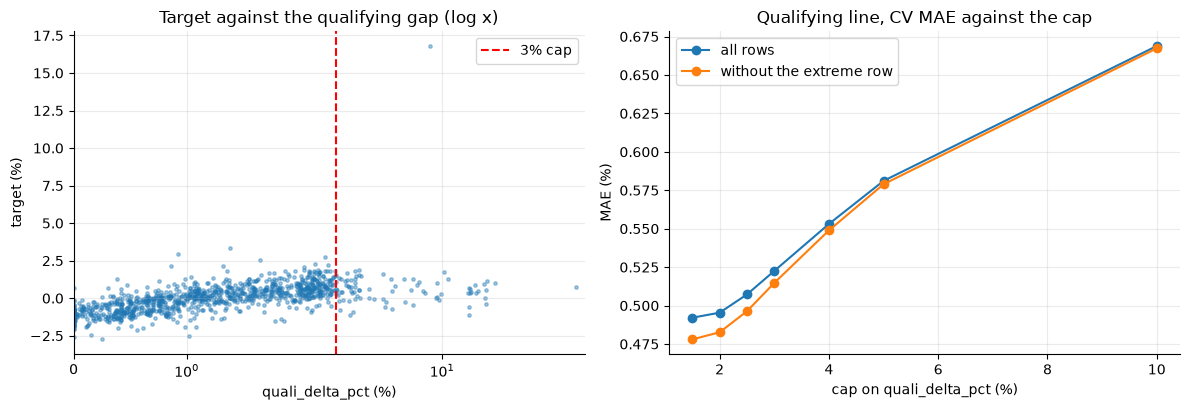

In [25]:
spare = base[base[TARGET] < base[TARGET].max()].reset_index(drop=True)
spare_index = spare.merge(race_order.reset_index(names="race"), on=["year", "round"])["race"].to_numpy()
print("same comparison without the extreme target row (fitting and scoring):")
out = []
for cap in (2, 3, 5, None):
    mean, sd = cv_mae(cap, spare, spare_index)
    out.append({"cap": cap if cap else "none", "CV MAE": mean, "sd over folds": sd})
print(pd.DataFrame(out).round(3).to_string(index=False))
rho_all = stats.spearmanr(base["quali_delta_pct"], base[TARGET]).statistic
low = base[base["quali_delta_pct"] <= 3]
rho_low = stats.spearmanr(low["quali_delta_pct"], low[TARGET]).statistic
print(f"Spearman(quali_delta_pct, target): all rows {rho_all:.3f}; rows up to 3% {rho_low:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(base["quali_delta_pct"], base[TARGET], s=6, alpha=0.4)
ax[0].axvline(3, color="r", ls="--", label="3% cap")
ax[0].set(
    xscale="symlog",
    xlim=(0, 50),
    title="Target against the qualifying gap (log x)",
    xlabel="quali_delta_pct (%)",
    ylabel="target (%)",
)
ax[0].legend()
caps = [1.5, 2, 2.5, 3, 4, 5, 10]
ax[1].plot(caps, [cv_mae(c)[0] for c in caps], "o-", label="all rows")
ax[1].plot(caps, [cv_mae(c, spare, spare_index)[0] for c in caps], "o-", label="without the extreme row")
ax[1].set(title="Qualifying line, CV MAE against the cap", xlabel="cap on quali_delta_pct (%)", ylabel="MAE (%)")
ax[1].legend()
plt.tight_layout()
plt.show()

## Figures for the summary

In [26]:
FIGURES = ROOT / "docs" / "eda" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.savefig(FIGURES / name, dpi=100, bbox_inches="tight")
    plt.close(fig)
    print("saved", (FIGURES / name).relative_to(ROOT))


structural = {
    "sprint_pace_delta_pct": ~sprint,
    "fp_long_run_delta_pct": sprint,
    "fp_tyre_deg": sprint,
    "team_pace_this_circuit_prev": first_year,
}
rows = []
for column in NUMERIC:
    nan = valid[column].isna()
    if nan.sum() == 0:
        continue
    by_design = (nan & structural[column]).mean() * 100 if column in structural else 0.0
    rows.append((column, by_design, nan.mean() * 100 - by_design))
nan_table = (
    pd.DataFrame(rows, columns=["feature", "structural", "other"]).set_index("feature").sort_values("structural")
)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(nan_table.index, nan_table["structural"], label="structural (no sprint, no FP2, no earlier year)")
ax.barh(nan_table.index, nan_table["other"], left=nan_table["structural"], label="other")
ax.set(title="Missing values by feature (training rows)", xlabel="% of rows")
ax.legend(fontsize=8, loc="lower right")
save(fig, "04_missing_values.png")

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.scatter(valid["clean_laps"], valid[TARGET], s=7, alpha=0.5)
ax.axvline(10, color="grey", ls=":", label="current minimum (10 clean laps)")
ax.axvline(15, color="r", ls="--", label="suggested minimum (15)")
worst = valid.loc[valid[TARGET].idxmax()]
ax.annotate(
    "SAR, Zandvoort 2023\n13 clean laps, wet to dry",
    (worst["clean_laps"], worst[TARGET]),
    xytext=(30, 14.5),
    arrowprops={"arrowstyle": "->"},
)
ax.set(
    title="Target against clean laps of the driver", xlabel="clean laps in the race", ylabel="race_pace_delta_pct (%)"
)
ax.legend(fontsize=8, loc="center right")
save(fig, "05_target_vs_clean_laps.png")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(base["quali_delta_pct"], base[TARGET], s=6, alpha=0.4)
ax[0].axvline(3, color="r", ls="--", label="3% cap")
ax[0].set(
    xscale="symlog",
    xlim=(0, 50),
    ylim=(-3.5, 4),
    title="Target against the qualifying gap (log x)",
    xlabel="quali_delta_pct (%)",
    ylabel="target (%)",
)
ax[0].text(0.03, 0.03, "one point at 16.8% is off the scale", transform=ax[0].transAxes, fontsize=7)
ax[0].legend(loc="upper left")
caps = [1.5, 2, 2.5, 3, 4, 5, 10]
ax[1].plot(caps, [cv_mae(c)[0] for c in caps], "o-", label="all rows")
ax[1].plot(caps, [cv_mae(c, spare, spare_index)[0] for c in caps], "o-", label="without the extreme row")
ax[1].set(title="Qualifying line, cross-validated MAE by cap", xlabel="cap on quali_delta_pct (%)", ylabel="MAE (%)")
ax[1].legend()
save(fig, "06_quali_cap.png")

saved docs/eda/figures/04_missing_values.png
saved docs/eda/figures/05_target_vs_clean_laps.png
saved docs/eda/figures/06_quali_cap.png


## Findings

Suggested decisions (they reach `DECISIONS.md` in step 13, after the review of the summary). The first one changes a frozen contract, so it needs its line before any code:

1. **Raise the valid-row minimum from 10 to 15 clean laps.** The 9 rows with 10 to 14 clean laps have a target std of 5.2 and 3 of them are beyond ±2%, against 1% beyond ±2% among rows with 40 or more laps; from 15 laps on the spread is the same as for the rest (std 0.83). With the minimum at 15 the table keeps 1,041 rows (9 fewer, 0.9%), the excess kurtosis falls from 71.9 to -0.07 and RMSE/MAE from 1.43 to 1.25. It selects on lap count, a property of the data, not on the label, which dropping `|target| > 5` or winsorising would do (and the latter still leaves kurtosis at 0.15). It also removes the six rows of 2023 rounds 14 to 17 whose form features are inflated (driver form up to 6.1, team form up to 3.1) by that one target. The pooled field keeps the 10-lap rule for now: Phase 3 decides whether both thresholds move together.
2. **Keep the 3% cap on `quali_delta_pct`.** The qualifying line scores a cross-validated MAE of 0.523 with the cap and 0.682 without it (median dummy 0.727), and 0.515 against 0.671 once the extreme target row is set aside, with a spread over folds of 0.04 to 0.06. A lower cap does a little better (2%: 0.495; 1.5%: 0.492), inside that spread. The cap is a candidate to tune in Phase 4; nothing to change now.
3. **Apply the cap before `teammate_quali_gap`.** The gap reaches -30% and +43% (52 rows beyond 4 MAD, 11 beyond ±8%), always as a pair: Williams 2023 round 2 gives SAR +42.8% and ALB -30.0% because SAR was 45.6% slower than pole. The teammate who drove normally inherits the extreme. Computing the gap from capped times (or capping the gap) is the candidate; it changes a feature definition.
4. **Imputation per column** (all with the `median` or `mean` choice that the config already offers): use the median for `fp_long_run_delta_pct` (skew -4.1, one value at -12.2), `teammate_quali_gap` (skew 3.9) and `driver_pace_last3` (skew 1.0); mean and median are interchangeable for the other columns (gap under 0.16 standard deviations). No column is dropped. `humidity` and `wind_speed` stay exploration-only until `03` says otherwise.

What the data says, with no decision attached:

- **Most NaN are structural, not random.** `sprint_pace_delta_pct` (79%) is empty on every normal weekend; the FP2 features (43%) on every sprint weekend plus 25% of the rows of normal weekends; `team_pace_this_circuit_prev` (43%) in the whole first year (413 rows) and in 43 rows of four races whose circuit or team had no valid race the year before (Imola and Shanghai 2024, Alpine at Hungary 2024, Haas at Monaco 2025). `is_sprint_weekend` already tells the model why the first two are empty. Form features are empty only at a driver's or team's first valid race (28 and 20 rows). 70% of rows are complete once structural NaN are set aside.
- **The NaN carry little on their own.** The median target of the rows with FP2 missing against the rest is -0.09 with an interval that includes 0 ([-0.17, 0.03]); the same for sprint pace and driver form. `team_pace_this_circuit_prev` has [-0.14, -0.01], mixed up with the first year.
- **FP2 coverage is weak in some races, for real reasons.** Eight of 42 normal weekends have a long run for under 40% of the drivers and two (Suzuka 2024 and 2025) for none: a wet FP2, and one with repeated red flags. Per the spec risk this stays a decision about the definition, not a data patch.
- **Dropped rows are not random.** The valid-row rule drops 68 rows (6.1%), 58 with fewer than 10 clean laps and 10 with no qualifying time. It hits Williams (11.8%) and Alpine (11.6%) against Mercedes (1.8%): cars and drivers that crash or stop early. Rain makes no difference (5.4% against 6.3%).
- **The feature outliers are genuine.** The 85 rows (8.1%) with `quali_delta_pct` above 3% are wet or red-flagged qualifyings (58 with rain; only 1 of them reached Q3), mostly in 2023 (52): Zandvoort and Spa 2023, Silverstone 2024. The 45.6% of SAR in Jeddah 2023 is a 128.5 s lap with 8 laps run, a driver outside the 107% limit, and the source gives him no grid position (the same for BOT 2023 round 10: 2 training rows with a time and no `grid_position`). FP2 extremes (`fp_long_run_delta_pct` -12.2 for RUS, Melbourne 2023; `fp_tyre_deg` up to ±1.6 s per lap) come from single 5-lap runs in wet sessions: noisy, not wrong.
- **The extreme target is real lap times compared on unlike ground.** SAR at Zandvoort 2023 has 13 clean laps, all between laps 2 and 14, at a median of 89.9 s; the rest of the field on those same laps has 84.6 s, and its median over the whole race is 76.9 s. The race changed from wet to dry, so the driver is compared with a field that mostly ran later, on a faster track. It is a limit of the target definition in races with changing conditions; the next largest targets (3.3%, 2.9%) also come from rain races. Comparing on the same laps would change the target contract and is out of this spec.
- **No categorical problem.** `circuit_type` has 3 levels (permanent 659 rows and 35 races, street 225 and 12, hybrid 166 and 9); every circuit was raced at least twice; the 9 drivers with fewer than 25 rows are rookies and a driver is not a feature.